# GraphRAG desde cero (versión local, sin Neo4j)
### Grafos de conocimiento + recuperación híbrida, todo gratis en Colab

**Universidad de Santiago de Chile (USACH)**  
Diplomado de Inteligencia artificial aplicada a la industria tecnológica  
Reelaborado por Diego Fischer

*Basado en la guía de GraphRAG de Tomaz Bratanic (blog de Neo4j + LangChain). Esta versión reemplaza todo el stack de pago y servidores externos por herramientas **locales y gratuitas**: un grafo en memoria con **NetworkX**, un índice vectorial con **Chroma** y un **LLM abierto**, sin Neo4j, sin OpenAI y sin claves de API.*

---

En el cuaderno anterior construimos un RAG clásico (búsqueda vectorial sobre texto). Aquí damos el siguiente paso: **GraphRAG**, que además de buscar texto entiende **cómo se relacionan las cosas** entre sí, usando un **grafo de conocimiento**.

> **Sobre la migración:** el material original usaba una base de datos **Neo4j** en un servidor remoto (con credenciales escritas directamente en el código — algo que nunca debe hacerse y que aquí eliminamos) y modelos de **OpenAI** de pago. Nuestra versión hace lo mismo conceptualmente, pero todo corre dentro de Colab, sin cuentas ni costos.

---

## ¿Qué es GraphRAG y por qué?

El RAG vectorial del cuaderno anterior es excelente para preguntas del tipo *"¿qué dice el documento sobre X?"*. Pero tiene un punto ciego: **las relaciones**. Si preguntas *"¿qué conexión hay entre X e Y?"* o *"¿quiénes están vinculados a Z?"*, la búsqueda vectorial trae fragmentos sueltos y espera que el LLM "arme el puzzle" — a veces lo logra, a veces no.

Un **grafo de conocimiento** representa la información de otra forma: como **nodos** (las entidades: personas, lugares, obras) unidos por **aristas** (las relaciones entre ellas). Por ejemplo:

```
   (Gabriela Mistral) --nació en--> (Vicuña)
   (Gabriela Mistral) --ganó--> (Premio Nobel de Literatura)
```

Con esa estructura, responder *"¿dónde nació Gabriela Mistral?"* es seguir una arista, no adivinar entre párrafos.

**GraphRAG combina lo mejor de ambos mundos** (recuperación *híbrida*):

- **Recuperación estructurada (grafo):** encuentra las entidades de la pregunta en el grafo y devuelve su vecindario de relaciones. Ideal para lo relacional.
- **Recuperación no estructurada (vectorial):** busca los fragmentos de texto más parecidos. Ideal para detalles y matices.

La analogía: el RAG vectorial es como tener un montón de párrafos subrayados; el grafo de conocimiento es como tener el **mapa** de cómo todo se conecta. GraphRAG usa ambos.

### ¿Y cómo se construye el grafo?

Aquí está el truco moderno: **usamos un LLM para leer el texto y extraer las relaciones** en forma de tripletas `(sujeto, relación, objeto)`. Antes, construir un grafo de conocimiento era un trabajo manual enorme; hoy un LLM lo automatiza. Eso sí — y es una lección clave — **la calidad del grafo depende mucho del LLM que extrae**. Con un modelo abierto y pequeño (como el nuestro) el grafo saldrá más rústico que con un modelo gigante de pago. Es el costo real de la independencia.

---

## Fase 1 — Instalación y modelos

Instalamos LangChain (para cargar Wikipedia y trocear), Chroma, el modelo de embeddings, NetworkX para el grafo y `transformers` para el LLM abierto.

> **Activa la GPU** (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*). El LLM que extrae el grafo hace bastante trabajo; en CPU sería muy lento.

In [1]:
!pip install -q -U langchain-community langchain-text-splitters langchain-huggingface langchain-chroma sentence-transformers chromadb wikipedia transformers accelerate networkx matplotlib

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 64.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 72.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.9/178.9 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━

### Cargar el modelo de embeddings y el LLM

- **Embeddings:** el mismo modelo multilingüe del cuaderno anterior (`paraphrase-multilingual-MiniLM-L12-v2`), para la búsqueda vectorial.
- **LLM:** `Qwen2.5-3B-Instruct`, un modelo abierto (licencia Apache-2.0, sin restricciones de acceso) que sigue instrucciones razonablemente bien, maneja español y cabe en la GPU gratuita de Colab. Lo usaremos para **tres** tareas: extraer el grafo, detectar entidades en las preguntas y redactar la respuesta final.

> **Si tienes poca memoria de GPU** puedes bajar a `Qwen/Qwen2.5-1.5B-Instruct` (más rápido, grafo algo más pobre). **Si tienes más**, `Qwen/Qwen2.5-7B-Instruct` (con cuantización de 4 bits) extrae grafos notablemente mejores.

In [2]:
import torch
from langchain_huggingface import HuggingFaceEmbeddings
from transformers import AutoModelForCausalLM, AutoTokenizer

# --- Embeddings ---
embeddings = HuggingFaceEmbeddings(
    model_name='sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

# --- LLM abierto ---
MODELO_LLM = 'Qwen/Qwen2.5-3B-Instruct'
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODELO_LLM)
model = AutoModelForCausalLM.from_pretrained(
    MODELO_LLM, torch_dtype=dtype, device_map='auto')

print('Modelos cargados. GPU:', torch.cuda.is_available())

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelos cargados. GPU: True


### Una función para "hablarle" al LLM

Definimos un helper `generar(instruccion)` que aplica la plantilla de chat del modelo y devuelve solo su respuesta. Lo reutilizaremos en todas las fases. Usamos generación **determinista** (`do_sample=False`) para que los resultados sean reproducibles.

In [3]:
def generar(instruccion, max_new_tokens=512):
    """Envía una instrucción al LLM y devuelve su respuesta en texto."""
    mensajes = [{'role': 'user', 'content': instruccion}]
    texto = tokenizer.apply_chat_template(
        mensajes, tokenize=False, add_generation_prompt=True)
    entradas = tokenizer([texto], return_tensors='pt').to(model.device)
    with torch.no_grad():
        salida = model.generate(**entradas, max_new_tokens=max_new_tokens,
                                do_sample=False)
    # Nos quedamos solo con los tokens nuevos (la respuesta)
    nuevos = salida[0][entradas.input_ids.shape[1]:]
    return tokenizer.decode(nuevos, skip_special_tokens=True).strip()

# Prueba
print(generar('Saluda en una sola frase.', max_new_tokens=40))

¡Hola! ¿Cómo estás hoy?


## Fase 2 — Ingesta de datos

Cargamos un artículo de Wikipedia **en español** — usamos el de **Gabriela Mistral**, rico en relaciones (nacimiento, premios, obras, lugares). Luego lo troceamos, igual que en el RAG clásico.

In [5]:
import requests
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Bajar el artículo directo desde la API de Wikipedia (más robusto que WikipediaLoader)
def cargar_wikipedia(titulo, lang='es'):
    url = f'https://{lang}.wikipedia.org/w/api.php'
    params = {'action': 'query', 'prop': 'extracts', 'explaintext': 1,
              'format': 'json', 'redirects': 1, 'titles': titulo}
    headers = {'User-Agent': 'usach-curso-ia/1.0 (contacto@usach.cl)'}
    r = requests.get(url, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    paginas = r.json()['query']['pages']
    texto = next(iter(paginas.values()))['extract']
    return [Document(page_content=texto, metadata={'title': titulo})]

raw = cargar_wikipedia('Gabriela Mistral', lang='es')
print('Título cargado:', raw[0].metadata['title'])
print('Caracteres    :', len(raw[0].page_content))

# Trocear
splitter = RecursiveCharacterTextSplitter(chunk_size=1200, chunk_overlap=100)
chunks = splitter.split_documents(raw)
print('Fragmentos    :', len(chunks))

Título cargado: Gabriela Mistral
Caracteres    : 53319
Fragmentos    : 66


## Fase 3 — Construir el grafo de conocimiento

Aquí está el corazón de GraphRAG. Le pedimos al LLM que lea cada fragmento y extraiga las relaciones como **tripletas** en un formato simple y a prueba de errores:

```
SUJETO | RELACIÓN | OBJETO
```

Elegimos este formato de líneas (en vez de JSON) justamente porque es **robusto**: un modelo pequeño se equivoca mucho más armando JSON estricto que escribiendo líneas con separadores. Luego parseamos con tolerancia, descartando lo que venga mal formado.

> Para que corra en pocos minutos, procesamos los primeros fragmentos. Cada fragmento es una llamada al LLM, así que más fragmentos = grafo más completo pero más lento.

In [6]:
PROMPT_EXTRACCION = """Extrae las relaciones del texto como tripletas.
Formato EXACTO, una por línea:
SUJETO | RELACIÓN | OBJETO

Reglas:
- Usa nombres cortos y concretos para sujeto y objeto (entidades: personas, lugares,
  obras, instituciones, fechas).
- La relación es un verbo o frase corta (ej: nació en, ganó, escribió, trabajó en).
- No inventes nada que no esté en el texto. No agregues explicaciones ni numeración.

Texto:
{texto}

Tripletas:"""

def extraer_tripletas(texto):
    """Pide al LLM las tripletas de un texto y las parsea con tolerancia."""
    salida = generar(PROMPT_EXTRACCION.format(texto=texto), max_new_tokens=400)
    tripletas = []
    for linea in salida.split('\n'):
        if linea.count('|') >= 2:
            partes = [p.strip() for p in linea.split('|')]
            suj, rel, obj = partes[0], partes[1], partes[2]
            # Descartamos líneas vacías o de encabezado
            if suj and rel and obj and suj.upper() != 'SUJETO':
                tripletas.append((suj, rel, obj))
    return tripletas

In [7]:
N_FRAGMENTOS = 5   # sube para un grafo más completo (más lento)

todas_las_tripletas = []
for i, ch in enumerate(chunks[:N_FRAGMENTOS]):
    tr = extraer_tripletas(ch.page_content)
    todas_las_tripletas.extend(tr)
    print(f'Fragmento {i+1}/{N_FRAGMENTOS}: {len(tr)} tripletas extraídas')

print(f'\nTotal de tripletas: {len(todas_las_tripletas)}')
print('\nEjemplos:')
for t in todas_las_tripletas[:8]:
    print(f'  {t[0]}  —[{t[1]}]→  {t[2]}')

Fragmento 1/5: 4 tripletas extraídas
Fragmento 2/5: 6 tripletas extraídas
Fragmento 3/5: 6 tripletas extraídas
Fragmento 4/5: 1 tripletas extraídas
Fragmento 5/5: 9 tripletas extraídas

Total de tripletas: 26

Ejemplos:
  Lucila de María Godoy Alcayaga  —[nació en]→  Vicuña
  Gabriela Mistral  —[nació en]→  7 de abril de 1889
  Gabriela Mistral  —[falleció en]→  Hempstead
  Gabriela Mistral  —[vivió desde]→  1889 hasta 1957
  Lucila de María Godoy Alcayaga  —[nació en]→  Vicuña
  Vicuña  —[tiene]→  museo en honor a Gabriela Mistral
  Gabriela Mistral  —[pasó]→  infancia en diversos localidades del valle de Elqui
  Gabriela Mistral  —[se trasladó]→  de Vicuña a La Unión


### Armar el grafo con NetworkX

Convertimos las tripletas en un grafo dirigido de **NetworkX**: cada sujeto y objeto es un nodo, y cada relación una arista etiquetada. Este grafo vive en memoria — no necesitamos Neo4j ni ninguna base de datos externa.

In [8]:
import networkx as nx

G = nx.DiGraph()
for suj, rel, obj in todas_las_tripletas:
    G.add_edge(suj, obj, rel=rel)

print(f'Grafo construido: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas')

Grafo construido: 33 nodos, 23 aristas


### Visualizar el grafo

Dibujamos el grafo para verlo con nuestros propios ojos. Para grafos con muchos nodos queda algo apretado, pero permite apreciar la estructura de relaciones.

> Para una visualización **interactiva** (arrastrable, con zoom) puedes usar la librería `pyvis`; aquí usamos Matplotlib por simplicidad y para que no dependa de widgets del navegador.

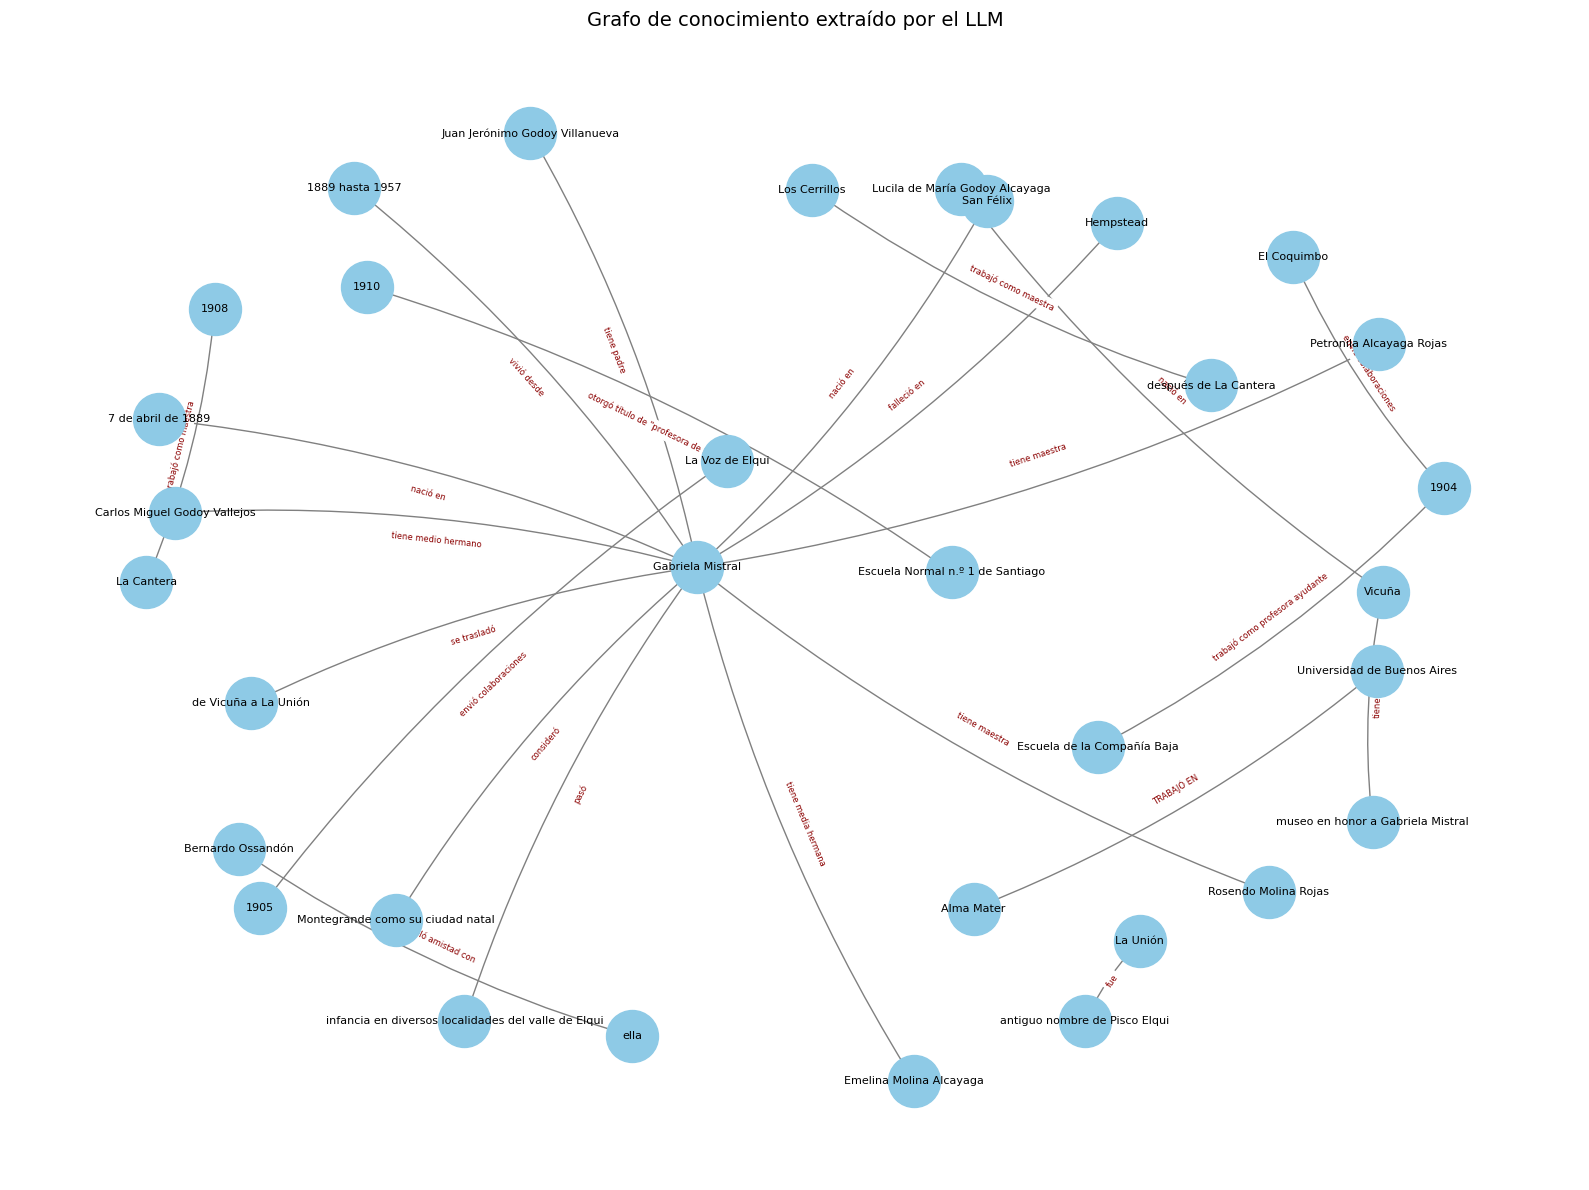

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, k=0.9, seed=42)

nx.draw_networkx_nodes(G, pos, node_color='#8ecae6', node_size=1400)
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True,
                       arrowsize=15, connectionstyle='arc3,rad=0.08')
nx.draw_networkx_labels(G, pos, font_size=8)

etiquetas = nx.get_edge_attributes(G, 'rel')
nx.draw_networkx_edge_labels(G, pos, edge_labels=etiquetas, font_size=6,
                             font_color='darkred')

plt.title('Grafo de conocimiento extraído por el LLM', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

## Fase 4 — Índice vectorial (recuperación no estructurada)

Además del grafo, construimos el índice vectorial clásico sobre los mismos fragmentos, con Chroma. Este será nuestro segundo recuperador — el que aporta el texto con detalles y matices que el grafo, más esquemático, no captura.

In [10]:
from langchain_chroma import Chroma

vectorstore = Chroma.from_documents(documents=chunks, embedding=embeddings)
print(f'Índice vectorial creado con {len(chunks)} fragmentos.')

Índice vectorial creado con 66 fragmentos.


## Fase 5 — Recuperación híbrida

Ahora combinamos ambos recuperadores. El flujo para cada pregunta:

1. **Detectar entidades** en la pregunta (con el LLM).
2. **Recuperador de grafo:** buscar esas entidades entre los nodos y devolver su vecindario de relaciones.
3. **Recuperador vectorial:** traer los fragmentos de texto más parecidos.
4. **Combinar** ambos contextos.

### Recuperador de grafo

In [11]:
def detectar_entidades(pregunta):
    """Usa el LLM para extraer nombres de entidades de la pregunta."""
    p = ('Extrae los nombres propios (personas, lugares, obras, instituciones) '
         'de esta pregunta. Devuélvelos separados por comas, sin explicación.\n\n'
         f'Pregunta: {pregunta}\n\nEntidades:')
    resp = generar(p, max_new_tokens=50)
    return [e.strip() for e in resp.replace('\n', ',').split(',') if e.strip()]


def recuperar_del_grafo(pregunta):
    """Devuelve las relaciones del grafo cercanas a las entidades de la pregunta."""
    entidades = detectar_entidades(pregunta)
    lineas = []
    for ent in entidades:
        for nodo in G.nodes:
            # coincidencia flexible (contención en cualquier sentido)
            if ent.lower() in nodo.lower() or nodo.lower() in ent.lower():
                for _, obj, d in G.out_edges(nodo, data=True):
                    lineas.append(f'{nodo} —{d["rel"]}→ {obj}')
                for suj, _, d in G.in_edges(nodo, data=True):
                    lineas.append(f'{suj} —{d["rel"]}→ {nodo}')
    # quitar duplicados conservando el orden
    return list(dict.fromkeys(lineas))

# Prueba
print('Entidades detectadas:', detectar_entidades('¿Dónde nació Gabriela Mistral?'))
print('\nRelaciones del grafo:')
for l in recuperar_del_grafo('¿Dónde nació Gabriela Mistral?'):
    print(' ', l)

Entidades detectadas: ['Gabriela Mistral']

Relaciones del grafo:
  Gabriela Mistral —nació en→ 7 de abril de 1889
  Gabriela Mistral —falleció en→ Hempstead
  Gabriela Mistral —vivió desde→ 1889 hasta 1957
  Gabriela Mistral —pasó→ infancia en diversos localidades del valle de Elqui
  Gabriela Mistral —se trasladó→ de Vicuña a La Unión
  Gabriela Mistral —consideró→ Montegrande como su ciudad natal
  Gabriela Mistral —nació en→ San Félix
  Gabriela Mistral —tiene medio hermano→ Carlos Miguel Godoy Vallejos
  Gabriela Mistral —tiene media hermana→ Emelina Molina Alcayaga
  Gabriela Mistral —tiene maestra→ Rosendo Molina Rojas
  Gabriela Mistral —tiene padre→ Juan Jerónimo Godoy Villanueva
  Gabriela Mistral —tiene maestra→ Petronila Alcayaga Rojas
  Vicuña —tiene→ museo en honor a Gabriela Mistral


### El recuperador híbrido completo

Unimos las dos fuentes en un solo bloque de contexto: primero los **datos estructurados** del grafo, luego el **texto** recuperado por vectores.

In [12]:
def recuperar_hibrido(pregunta, k=3):
    # 1) datos del grafo
    grafo = recuperar_del_grafo(pregunta)
    grafo_txt = '\n'.join(grafo) if grafo else '(sin relaciones encontradas)'

    # 2) texto por similitud vectorial
    docs = vectorstore.similarity_search(pregunta, k=k)
    texto_txt = '\n\n'.join(d.page_content for d in docs)

    return f"""Datos estructurados (grafo de conocimiento):
{grafo_txt}

Texto relacionado:
{texto_txt}"""

print(recuperar_hibrido('¿Qué premio ganó Gabriela Mistral?')[:900], '...')

Datos estructurados (grafo de conocimiento):
Gabriela Mistral —nació en→ 7 de abril de 1889
Gabriela Mistral —falleció en→ Hempstead
Gabriela Mistral —vivió desde→ 1889 hasta 1957
Gabriela Mistral —pasó→ infancia en diversos localidades del valle de Elqui
Gabriela Mistral —se trasladó→ de Vicuña a La Unión
Gabriela Mistral —consideró→ Montegrande como su ciudad natal
Gabriela Mistral —nació en→ San Félix
Gabriela Mistral —tiene medio hermano→ Carlos Miguel Godoy Vallejos
Gabriela Mistral —tiene media hermana→ Emelina Molina Alcayaga
Gabriela Mistral —tiene maestra→ Rosendo Molina Rojas
Gabriela Mistral —tiene padre→ Juan Jerónimo Godoy Villanueva
Gabriela Mistral —tiene maestra→ Petronila Alcayaga Rojas
Vicuña —tiene→ museo en honor a Gabriela Mistral

Texto relacionado:
Lucila de María Godoy Alcayaga​ (Vicuña, 7 de abril de 1889-Hempstead, 10 de enero de 1957),​ conocida como Gabriela M ...


## Fase 6 — La cadena GraphRAG y comparación

Finalmente, la función que responde: arma el contexto híbrido y se lo pasa al LLM con la instrucción de responder **solo con ese contexto**.

In [13]:
PROMPT_RESPUESTA = """Responde la pregunta usando ÚNICAMENTE el siguiente contexto.
Si la respuesta no está, di que no tienes suficiente información. Sé conciso.

{contexto}

Pregunta: {pregunta}
Respuesta:"""

def responder(pregunta):
    contexto = recuperar_hibrido(pregunta)
    return generar(PROMPT_RESPUESTA.format(contexto=contexto, pregunta=pregunta),
                   max_new_tokens=200)

for q in ['¿Dónde nació Gabriela Mistral?',
          '¿Qué premio ganó y en qué año?',
          '¿Con qué lugares está relacionada?']:
    print(f'PREGUNTA : {q}')
    print(f'RESPUESTA: {responder(q)}\n')

PREGUNTA : ¿Dónde nació Gabriela Mistral?
RESPUESTA: Gabriela Mistral nació en San Félix.

PREGUNTA : ¿Qué premio ganó y en qué año?
RESPUESTA: Gabriela Mistral ganó el Premio Nobel de Literatura en 1945.

PREGUNTA : ¿Con qué lugares está relacionada?
RESPUESTA: Gabriela Mistral está relacionada con Chile, París, Madrid, y el valle de Elqui.



In [14]:
pregunta = '¿Con qué lugares está relacionada Gabriela Mistral?'

print('=== SOLO GRAFO (estructurado) ===')
for l in recuperar_del_grafo(pregunta):
    print(' ', l)

print('\n=== SOLO VECTORIAL (texto) ===')
for d in vectorstore.similarity_search(pregunta, k=2):
    print(' ', d.page_content[:150], '...')

print('\n=== RESPUESTA HÍBRIDA (grafo + texto) ===')
print(responder(pregunta))

=== SOLO GRAFO (estructurado) ===
  Gabriela Mistral —nació en→ 7 de abril de 1889
  Gabriela Mistral —falleció en→ Hempstead
  Gabriela Mistral —vivió desde→ 1889 hasta 1957
  Gabriela Mistral —pasó→ infancia en diversos localidades del valle de Elqui
  Gabriela Mistral —se trasladó→ de Vicuña a La Unión
  Gabriela Mistral —consideró→ Montegrande como su ciudad natal
  Gabriela Mistral —nació en→ San Félix
  Gabriela Mistral —tiene medio hermano→ Carlos Miguel Godoy Vallejos
  Gabriela Mistral —tiene media hermana→ Emelina Molina Alcayaga
  Gabriela Mistral —tiene maestra→ Rosendo Molina Rojas
  Gabriela Mistral —tiene padre→ Juan Jerónimo Godoy Villanueva
  Gabriela Mistral —tiene maestra→ Petronila Alcayaga Rojas
  Vicuña —tiene→ museo en honor a Gabriela Mistral

=== SOLO VECTORIAL (texto) ===
  == Enlaces externos ==
 Portal:Premios Nobel. Contenido relacionado con  Premios Nobel.
 Wikimedia Commons alberga una categoría multimedia sobre Gabr ...
  Gabriela Mistral nació en Vicuña

---
## Licencia y créditos

[![Licencia Creative Commons](https://i.creativecommons.org/l/by/4.0/88x31.png)](https://creativecommons.org/licenses/by/4.0/deed.es)

Este cuaderno está licenciado bajo una [Licencia Creative Commons Atribución 4.0 Internacional (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/deed.es). Puede compartirse y adaptarse, incluso con fines comerciales, siempre que se reconozca la autoría de forma adecuada.

**Reelaboración, migración a stack local y explicaciones:** Diego Fischer — Universidad de Santiago de Chile (USACH).  
**Material original:** guía de GraphRAG de Tomaz Bratanic (blog de Neo4j + LangChain).  
**Documento de ejemplo:** artículo *"Gabriela Mistral"* de Wikipedia en español.  
**Modelos:** `paraphrase-multilingual-MiniLM-L12-v2` y `Qwen/Qwen2.5-3B-Instruct` vía HuggingFace.